## Question 10. Computational Complexity and Transformer Design Trade-offs

Each head stores an $n\times n$ matrix of attention weights, so both time and memory grow with $n^2$. The benchmark times a NumPy forward pass and reports the memory of those weights.

## Code Execution

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

**Random source.** Seed 0 makes the projection matrices and the token inputs repeatable.

In [2]:
RNG = np.random.default_rng(0)

**Attention from Question 6.** The benchmark calls packed multi-head self-attention. The causal mask stays off.

In [4]:
def stable_softmax(x, axis=-1):
    """Numerically stable softmax along one axis."""
    x = np.asarray(x, dtype=float)
    shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_shifted = np.exp(shifted)
    return exp_shifted / np.sum(exp_shifted, axis=axis, keepdims=True)


def attention_with_mask(Q, K, V, causal=False):
    """One head: Q (nq, dk), K (nk, dk), V (nk, dv)."""
    scores = (Q @ K.T) / np.sqrt(Q.shape[1])
    if causal:
        if Q.shape[0] != K.shape[0]:
            raise ValueError("Causal mask requires equal query/key lengths")
        future = np.triu(np.ones(scores.shape, dtype=bool), k=1)
        scores = np.where(future, -np.inf, scores)
    weights = stable_softmax(scores, axis=-1)
    return weights @ V, weights


def multi_head_attention_general(
    query_states, key_value_states, W_Q, W_K, W_V, W_O, num_heads, causal=False
):
    """Packed-head attention: output (nq, d_model), weights (H, nq, nk)."""
    query_states = np.asarray(query_states, dtype=float)
    key_value_states = np.asarray(key_value_states, dtype=float)
    if (
        query_states.ndim != 2
        or key_value_states.ndim != 2
        or query_states.shape[1] != key_value_states.shape[1]
    ):
        raise ValueError("Input states must be 2D with the same model width")
    d_model = query_states.shape[1]
    if num_heads < 1 or d_model % num_heads:
        raise ValueError("num_heads must divide d_model")
    for W in (W_Q, W_K, W_V, W_O):
        if np.shape(W) != (d_model, d_model):
            raise ValueError("Packed projection matrices must be (d_model, d_model)")
    Q = query_states @ W_Q
    K = key_value_states @ W_K
    V = key_value_states @ W_V
    d_head = d_model // num_heads
    outputs, weights = [], []
    for h in range(num_heads):
        sl = slice(h * d_head, (h + 1) * d_head)
        head_output, head_weights = attention_with_mask(
            Q[:, sl], K[:, sl], V[:, sl], causal=causal
        )
        outputs.append(head_output)
        weights.append(head_weights)
    concatenated = np.concatenate(outputs, axis=-1)
    return concatenated @ W_O, np.stack(weights, axis=0)


def multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads):
    """Self-attention: output (n, d_model), weights (H, n, n)."""
    return multi_head_attention_general(X, X, W_Q, W_K, W_V, W_O, num_heads)

**Benchmark.** One warm-up pass is discarded. The recorded time is the median of three forward passes. The memory figure is `num_heads` $\times n \times n$ float64 weights, not the full activation footprint.

In [5]:
def benchmark_attention(seq_lengths, d_model, num_heads):
    """Return (n, median_seconds, weight_memory_bytes) for packed multi-head attention."""
    if d_model % num_heads:
        raise ValueError("num_heads must divide d_model")
    scale = 1 / np.sqrt(d_model)
    weights = [RNG.normal(0, scale, (d_model, d_model)) for _ in range(4)]
    rows = []
    for n in seq_lengths:
        X = RNG.normal(size=(n, d_model))
        multi_head_attention(X, *weights, num_heads)
        durations = []
        for _ in range(3):
            start = perf_counter()
            out, attn = multi_head_attention(X, *weights, num_heads)
            durations.append(perf_counter() - start)
        assert out.shape == (n, d_model) and attn.shape == (num_heads, n, n)
        assert np.all(np.isfinite(out)) and np.all(np.isfinite(attn))
        weight_bytes = num_heads * n * n * np.dtype(np.float64).itemsize
        rows.append((n, float(np.median(durations)), weight_bytes))
    return rows

**Run.** Sequence lengths $32, 64, 128, 256, 512$, with $d_{model}=64$ and $4$ heads.

In [6]:
benchmark_rows = benchmark_attention([32, 64, 128, 256, 512], d_model=64, num_heads=4)

/var/folders/yn/ymy12smn5_v3qsx0v8lj3c4w0000gn/T/ipykernel_10541/3579165692.py:39: RuntimeWarning: divide by zero encountered in matmul
  Q = query_states @ W_Q
/var/folders/yn/ymy12smn5_v3qsx0v8lj3c4w0000gn/T/ipykernel_10541/3579165692.py:39: RuntimeWarning: overflow encountered in matmul
  Q = query_states @ W_Q
/var/folders/yn/ymy12smn5_v3qsx0v8lj3c4w0000gn/T/ipykernel_10541/3579165692.py:39: RuntimeWarning: invalid value encountered in matmul
  Q = query_states @ W_Q
/var/folders/yn/ymy12smn5_v3qsx0v8lj3c4w0000gn/T/ipykernel_10541/3579165692.py:40: RuntimeWarning: divide by zero encountered in matmul
  K = key_value_states @ W_K
/var/folders/yn/ymy12smn5_v3qsx0v8lj3c4w0000gn/T/ipykernel_10541/3579165692.py:40: RuntimeWarning: overflow encountered in matmul
  K = key_value_states @ W_K
/var/folders/yn/ymy12smn5_v3qsx0v8lj3c4w0000gn/T/ipykernel_10541/3579165692.py:40: RuntimeWarning: invalid value encountered in matmul
  K = key_value_states @ W_K
/var/folders/yn/ymy12smn5_v3qsx0v8lj

**Table.** Median time is in milliseconds. Weight memory is in mebibytes.

In [7]:
print(" n   median ms   attention-weight MiB")
for n, seconds, mem in benchmark_rows:
    print(f"{n:3d}  {1000 * seconds:9.3f}   {mem / 2**20:9.3f}")

 n   median ms   attention-weight MiB
 32      0.244       0.031
 64      0.209       0.125
128      0.475       0.500
256      1.777       2.000
512     10.952       8.000


**Plot.** Median forward time against sequence length. The curve rises faster than linearly because the weight matrices are $n\times n$.

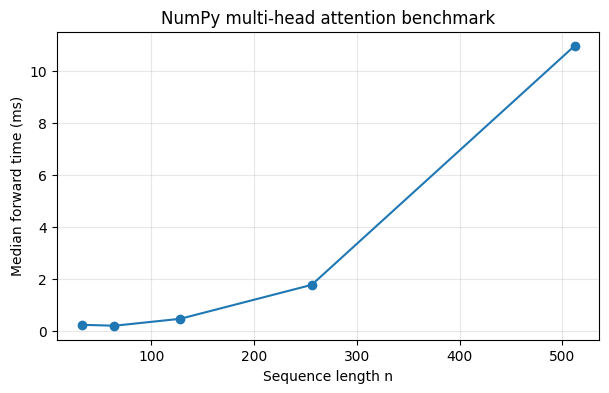

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    [row[0] for row in benchmark_rows],
    [1000 * row[1] for row in benchmark_rows],
    marker="o",
)
ax.set(
    xlabel="Sequence length n",
    ylabel="Median forward time (ms)",
    title="NumPy multi-head attention benchmark",
)
ax.grid(alpha=0.3)
plt.show()